# 25. KSC weather towers and the origin time

Notebook 24 predicts the airwave speed from two airport (ASOS) stations at 10 m. The KSC weather-tower
network (Spaceport Weather Archive, `data/ksc_weather_towers/`, 1-minute files, UTC) measures
temperature, humidity and wind at 6–204 ft on about 40 towers between LC-36 and the stations. Here:

* tower means over 00:50–01:10 UTC (`ksclib.weather.load_ksc_tower_1min`, `tower_means`);
* the temperature contrast between the coast and inland, and between 6 ft and 204 ft;
* the effective sound speed along each source-to-station path, interpolated from the towers at three
  heights (`weather.tower_path_sound_speed`), and the origin refitted from the notebook-24 onsets
  exactly as there ($t_0 = t_{onset,i} - T_i$ averaged over the six working infraBSUs).

No radiosonde was flown within 13 h of the event. The archive data are not quality controlled.

Output (`cfg.OUT_DIR / "25_ksc_towers"`): `tower_means.csv`, `tower_temperature_contrast.csv`,
`tower_path_speeds.csv`, `tower_origin.csv`, `ksc_towers.png`. Needs `24_origin_time/origin_time_picks.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ksclib import weather
import newglenn_config as cfg

OUT = cfg.output_dir('25_ksc_towers')
O = cfg.OUT_DIR
O_CFG = cfg.ORIGIN
LAT0, LON0 = cfg.EVENT.site_lat, cfg.EVENT.site_lon
WORKING = ['B20', 'B14', 'B29', 'B05']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

files = sorted((cfg.PAPER_DIR / 'data' / 'ksc_weather_towers').glob('WT_1MIN_*.dat'))
towers = weather.load_ksc_tower_1min(files)
print(len(files), 'files,', towers.datetime_utc.min(), 'to', towers.datetime_utc.max(), ';',
      towers.station.nunique(), 'towers')
means = weather.tower_means(towers, '2026-05-29 00:50', '2026-05-29 01:10')
area = means[means.lat.between(28.42, 28.66) & means.lon.between(-80.70, -80.50)]
means.to_csv(OUT / 'tower_means.csv', index=False)
spd, frm = weather.wind_from_uv(area.wind_u_east_mps, area.wind_v_north_mps)
display(area.assign(speed_mps=spd, from_deg=frm).drop(columns=['wind_u_east_mps', 'wind_v_north_mps'])
        .dropna(subset=['temperature_c', 'speed_mps'], how='all').round(2))

91 files, 2026-05-29 00:00:00+00:00 to 2026-05-29 01:30:00+00:00 ; 35 towers


,station,height_ft,lat,lon,height_m,temperature_c,relative_humidity_percent,n,speed_mps,from_deg
0,0001,6.0,28.43,-80.57,1.83,26.71,88.38,21,NaN,NaN
1,0001,12.0,28.43,-80.57,3.66,NaN,NaN,21,1.89,288.16
2,0001,54.0,28.43,-80.57,16.46,26.68,91.14,21,3.18,282.43
3,0002,6.0,28.44,-80.56,1.83,26.31,90.67,21,NaN,NaN
4,0002,12.0,28.44,-80.56,3.66,NaN,NaN,21,1.17,298.08
...,...,...,...,...,...,...,...,...,...,...
77,0803,12.0,28.46,-80.67,3.66,NaN,NaN,21,0.55,304.42
78,0803,54.0,28.46,-80.67,16.46,25.29,97.05,21,1.34,297.19
79,0805,6.0,28.52,-80.70,1.83,24.93,96.00,21,NaN,NaN
80,0805,12.0,28.52,-80.70,3.66,NaN,NaN,21,0.02,265.00


## Temperature: coast against inland, and with height

In [2]:
stt = pd.read_csv(O / '21_station_map' / 'station_table.csv').set_index('station')
def km(lat, lon, la, lo):
    return np.hypot((lon - lo) * 111.32 * np.cos(np.radians(lat)), (lat - la) * 110.57)
t6 = area[area.height_ft == 6].dropna(subset=['temperature_c']).copy()
t6['d_pad_km'] = km(t6.lat, t6.lon, LAT0, LON0)
t6['d_sta_km'] = [min(km(r.lat, r.lon, stt.loc[s, 'lat'], stt.loc[s, 'lon']) for s in WORKING) for _, r in t6.iterrows()]
coast = t6[t6.d_pad_km < 8]
inland = t6[t6.d_sta_km < 6]
tall = means[means.height_ft.isin([6, 204])].pivot_table(index='station', columns='height_ft', values='temperature_c').dropna()
tall = tall[tall.index.isin(area.station)]
contrast = pd.DataFrame([
    dict(quantity='6 ft temperature, towers < 8 km from LC-36 (C)', lo=coast.temperature_c.min(), hi=coast.temperature_c.max(), n=len(coast)),
    dict(quantity='6 ft temperature, towers < 6 km from a working station (C)', lo=inland.temperature_c.min(), hi=inland.temperature_c.max(), n=len(inland)),
    dict(quantity='204 ft minus 6 ft temperature (C)', lo=(tall[204] - tall[6]).min(), hi=(tall[204] - tall[6]).max(), n=len(tall)),
])
contrast.to_csv(OUT / 'tower_temperature_contrast.csv', index=False)
display(contrast.round(2))

,quantity,lo,hi,n
0,"6 ft temperature, towers < 8 km from LC-36 (C)",25.83,26.71,7
1,"6 ft temperature, towers < 6 km from a working...",24.91,26.50,9
2,204 ft minus 6 ft temperature (C),-0.78,0.17,4


## Path sound speeds and the origin

In [3]:
picks = pd.read_csv(O / '24_origin_time' / 'origin_time_picks.csv')
fit24 = pd.read_csv(O / '24_origin_time' / 'origin_time_fit.csv')
w24 = pd.read_csv(O / '24_origin_time' / 'weather_at_origin.csv')
P = float(w24.set_index('station').loc[cfg.EVENT.raw['weather']['stations']].pressure_pa.mean())
LEVELS = [('6 ft T, 12 ft wind', 6, 12), ('54 ft', 54, 54), ('204 ft', 204, 204)]
rows = []
for lab, hT, hW in LEVELS:
    for s in WORKING:
        r = weather.tower_path_sound_speed(means, LAT0, LON0, stt.loc[s, 'lat'], stt.loc[s, 'lon'],
                                           height_ft_temperature=hT, height_ft_wind=hW, pressure_pa=P)
        rows.append(dict(level=lab, station=s, **r))
paths = pd.DataFrame(rows)
paths.to_csv(OUT / 'tower_path_speeds.csv', index=False)
display(paths.round(2))

fits = []
for lab, _, _ in LEVELS:
    tt = paths[paths.level == lab].set_index('station').travel_time_s
    # the path length from the tower grid matches picks.distance_m to < 0.1%; use the travel time per metre
    per_m = tt / paths[paths.level == lab].set_index('station').length_m
    t0i = picks.onset_05 - picks.station.map(per_m) * picks.distance_m
    c = paths[paths.level == lab].c_path_mps
    fits.append(dict(model='towers, ' + lab, t0_s=t0i.mean(), spread_s=t0i.std(ddof=1),
                     c_min=c.min(), c_max=c.max()))
b24 = fit24[(fit24.onset == 'onset_05') & (fit24.model == 'weather + wind')].iloc[0]
fits.append(dict(model='ASOS (notebook 24)', t0_s=b24.t0_s, spread_s=b24.spread_s, c_min=np.nan, c_max=np.nan))
fits = pd.DataFrame(fits)
fits['shift_vs_asos_s'] = fits.t0_s - b24.t0_s
fits['origin_time'] = [str(O_CFG + x)[:23] for x in fits.t0_s]
fits.to_csv(OUT / 'tower_origin.csv', index=False)
display(fits.round(3))

,level,station,length_m,travel_time_s,c_path_mps,c0_mean_mps,wind_along_path_mps
0,"6 ft T, 12 ft wind",B20,11765.71,33.86,347.49,348.58,-1.09
1,"6 ft T, 12 ft wind",B14,19269.57,55.49,347.28,348.48,-1.20
2,"6 ft T, 12 ft wind",B29,20973.63,60.38,347.36,348.33,-0.98
3,"6 ft T, 12 ft wind",B05,21265.33,61.23,347.33,348.40,-1.07
4,54 ft,B20,11765.71,33.92,346.89,348.65,-1.77
5,54 ft,B14,19269.57,55.63,346.41,348.54,-2.13
6,54 ft,B29,20973.63,60.52,346.55,348.40,-1.85
7,54 ft,B05,21265.33,61.38,346.43,348.47,-2.03
8,204 ft,B20,11765.71,34.03,345.78,348.41,-2.63
9,204 ft,B14,19269.57,55.82,345.18,348.30,-3.12


,model,t0_s,spread_s,c_min,c_max,shift_vs_asos_s,origin_time
0,"towers, 6 ft T, 12 ft wind",0.048,0.298,347.279,347.488,0.051,2026-05-29T01:00:02.418
1,"towers, 54 ft",-0.081,0.276,346.414,346.887,-0.078,2026-05-29T01:00:02.289
2,"towers, 204 ft",-0.293,0.211,344.731,345.782,-0.291,2026-05-29T01:00:02.076
3,ASOS (notebook 24),-0.002,0.265,NaN,NaN,0.000,2026-05-29T01:00:02.367


## Figure

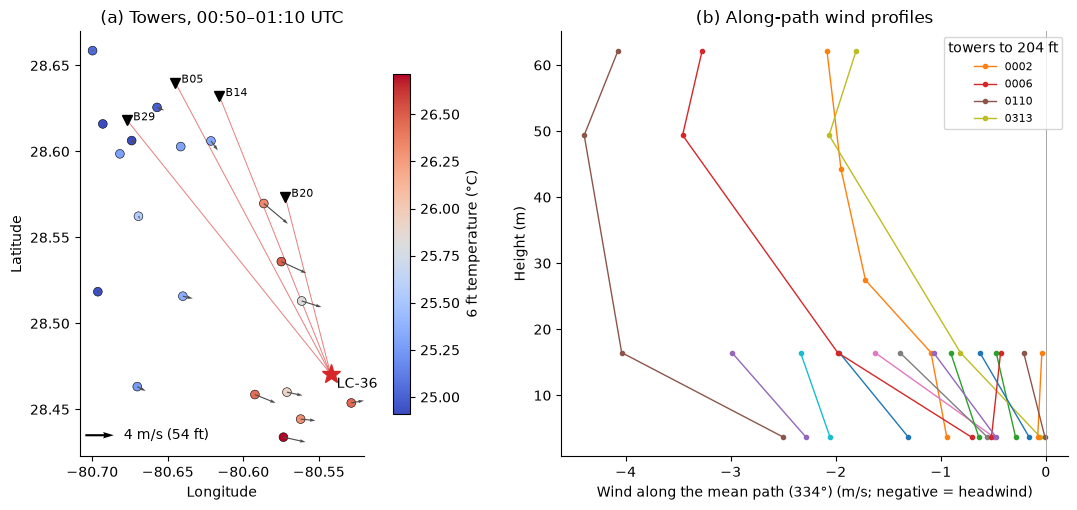

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1.15, 1]})
ax = axs[0]
sc = ax.scatter(t6.lon, t6.lat, c=t6.temperature_c, cmap='coolwarm', s=40, edgecolor='k', lw=0.4, zorder=3)
fig.colorbar(sc, ax=ax, label='6 ft temperature (°C)', shrink=0.8)
w54 = area[area.height_ft == 54].dropna(subset=['wind_u_east_mps'])
ax.quiver(w54.lon, w54.lat, w54.wind_u_east_mps, w54.wind_v_north_mps, scale=40, width=0.004, color='0.3', zorder=4)
ax.quiverkey(ax.quiver([], [], [], [], scale=40), 0.12, 0.05, 4, '4 m/s (54 ft)', labelpos='E')
ax.plot(LON0, LAT0, '*', ms=14, color='#d62728', zorder=5)
ax.text(LON0 + 0.004, LAT0 - 0.008, 'LC-36')
for s in WORKING:
    ax.plot([LON0, stt.loc[s, 'lon']], [LAT0, stt.loc[s, 'lat']], '-', color='#d62728', lw=0.7, alpha=0.6)
    ax.plot(stt.loc[s, 'lon'], stt.loc[s, 'lat'], 'v', color='k', ms=7, zorder=5)
    ax.text(stt.loc[s, 'lon'] + 0.004, stt.loc[s, 'lat'], s, fontsize=8)
ax.set(xlabel='Longitude', ylabel='Latitude', aspect=1 / np.cos(np.radians(28.55)), title='(a) Towers, 00:50–01:10 UTC')
ax = axs[1]
az = np.mean([np.degrees(np.arctan2((stt.loc[s, 'lon'] - LON0) * np.cos(np.radians(LAT0)), stt.loc[s, 'lat'] - LAT0)) for s in WORKING]) % 360
for tid, g in area.groupby('station'):
    g = g.sort_values('height_m')
    ww = weather.along_ray_wind_component(g.wind_u_east_mps, g.wind_v_north_mps, az)
    ok = np.isfinite(ww)
    if ok.sum() >= 2:
        ax.plot(ww[ok], g.height_m[ok], 'o-', ms=3, lw=1, label=tid if g.height_ft.max() >= 150 else None)
ax.axvline(0, color='0.6', lw=0.6)
ax.set(xlabel=f'Wind along the mean path ({az:.0f}°) (m/s; negative = headwind)', ylabel='Height (m)',
       title='(b) Along-path wind profiles')
ax.legend(title='towers to 204 ft', fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'ksc_towers.png', dpi=150, bbox_inches='tight')

## Summary

The airport weather of notebook 24 is confirmed near the ground: tower temperature, humidity and wind at
6–54 ft give path speeds and an origin within about 0.1 s of it. The towers show no surface inversion
at these heights (204 ft is within a few tenths of a degree of 6 ft), inland air about 1 °C cooler than
at the coast, and a headwind that strengthens with height. With the 204 ft towers the speed is lower, the
origin about 0.3 s earlier and the station spread smaller.